In [1]:
# STEP 1: Import the required libraries
# Pandas      -> Used for data loading, cleaning , manipulation, and analysis.
# Matplotlib  -> Used for creating and customizing charts.
# Seaborn     -> Used for statistical visualizations.

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# STEP 2: Load the raw Excel dataset
df = pd.read_excel("Superstore_Raw_Noisy.xlsx")

In [6]:
# STEP 3: Display the first 5 rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,6217,CA-2015-161711,11/28/2015,12/3/2015,Second Class,MC-17425,Mark Cousins,Corporate,United States,New York City,...,10035.0,East,OFF-EN-10001539,Office Supplies,Envelopes,Staple envelope,62.240,8,0.0,29.2528
1,569,CA-2017-156951,10/1/2017,10/8/2017,Standard Class,EB-13840,Ellis Ballard,Corporate,United States,Seattle,...,98105.0,West,OFF-PA-10004451,Office Supplies,Paper,Xerox 222,19.440,3,0.0,9.3312
2,8268,CA-2017-121790,1/30/2017,2/6/2017,Same Day,LP-17095,NaN,Consumer,United States,Aurora,...,60505.0,Central,FUR-TA-10003469,Furniture,Tables,Balt Split Level Computer Training Table,69.375,1,0.5,-47.1750
3,9698,CA-2016-122511,3/11/2016,2016/03/11,Same Day,BT-11485,Brad Thomas,Home Office,United States,Philadelphia,...,19140.0,East,FUR-FU-10001037,Furniture,Furnishings,"DAX Charcoal/Nickel-Tone Document Frame, 5 x 7",30.336,4,0.2,9.4800
4,9992,CA-2017-121258,2/26/2017,03/03/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932


In [7]:
# STEP 4: Check the dataset dimensions
df.shape

(10093, 21)

In [8]:
# STEP 5: Display all column names

df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [9]:
# STEP 6: Inspect data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10093 entries, 0 to 10092
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10093 non-null  int64  
 1   Order ID       10093 non-null  str    
 2   Order Date     10093 non-null  str    
 3   Ship Date      10093 non-null  str    
 4   Ship Mode      10013 non-null  str    
 5   Customer ID    10093 non-null  str    
 6   Customer Name  9944 non-null   str    
 7   Segment        10013 non-null  str    
 8   Country        10093 non-null  str    
 9   City           9993 non-null   str    
 10  State          10093 non-null  str    
 11  Postal Code    9893 non-null   float64
 12  Region         10093 non-null  str    
 13  Product ID     10093 non-null  str    
 14  Category       10093 non-null  str    
 15  Sub-Category   10093 non-null  str    
 16  Product Name   10093 non-null  str    
 17  Sales          10093 non-null  float64
 18  Quantity       10

In [10]:
# DATA CLEANING PLAN

# 1. Check and handle missing values
#    - Ship Date
#    - Customer Name
#    - Segment
#    - City
#    - Postal Code
#    - Discount
#    - Profit

# 2. Check and remove duplicate rows
#    - Identify completely duplicated records.
#    - Verify duplicates before removing them.

# 3. Fix incorrect data types
#    - Convert Order Date to datetime.
#    - Convert Ship Date to datetime.
#    - Review Postal Code because it is currently float64.
#    - Make sure Sales, Quantity, Discount, and Profit
#      have appropriate numeric data types.

# 4. Check text consistency
#    - Remove unnecessary leading/trailing spaces.
#    - Check inconsistent capitalization.
#    - Standardize values in categorical columns such as:
#      Ship Mode, Segment, Region, Category, and Sub-Category.

# 5. Check numeric values
#    - Sales should not contain invalid negative values.
#    - Quantity should be greater than zero.
#    - Discount should be within a realistic range.
#    - Check Profit for unusual or invalid values.

# 6. Check date validity
#    - Verify that Order Date contains valid dates.
#    - Verify that Ship Date contains valid dates.
#    - Check whether Ship Date occurs after Order Date.

# 7. Check categorical values
#    - Find unexpected or misspelled categories.
#    - Standardize inconsistent category names.

# 8. Check ID columns
#    - Check Row ID uniqueness.
#    - Check Order ID format.
#    - Check Customer ID and Product ID consistency.

# 9. Check outliers
#    - Identify unusual Sales values.
#    - Identify unusual Profit values.
#    - Investigate extreme Discount or Quantity values.

# 10. Final validation
#     - Confirm no unintended missing values remain.
#     - Confirm data types are correct.
#     - Confirm duplicates are handled.
#     - Confirm categorical values are standardized.
#     - Confirm the cleaned dataset is ready for EDA.


In [11]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode         80
Customer ID        0
Customer Name    149
Segment           80
Country            0
City             100
State              0
Postal Code      200
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount         100
Profit            79
dtype: int64

In [12]:
# STEP 8: Check for duplicate rows
# duplicated() identifies rows that are exact duplicates
# of another row in the dataset.
# sum() counts how many duplicate rows exist.
# We will only remove duplicates after confirming the result.

df.duplicated().sum()

np.int64(41)

In [13]:
# STEP 9: Display the duplicate rows

duplicates = df[df.duplicated(keep = False)]
duplicates

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
19,190,CA-2015-102281,10/12/2015,10/14/2015,First Class,MP-17470,Mark Packer,Home Office,United States,New York City,...,10035.0,East,FUR-BO-10002613,Furniture,Bookcases,"Atlantic Metals Mobile 4-Shelf Bookcases, Cust...",899.136,4,0.2,112.3920
168,2882,CA-2016-102932,9/19/2016,9/23/2016,Second Class,SD-20485,Shirley Daniels,Home Office,United States,Orange,...,7050.0,East,OFF-SU-10000381,Office Supplies,Supplies,Acme Forged Steel Scissors with Black Enamel H...,27.930,3,0.0,8.0997
307,3152,CA-2015-147830,12/15/2015,12/18/2015,First Class,NF-18385,Natalie Fritzler,Consumer,United States,NaN,...,43055.0,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,1799.994,2,0.7,-2639.9912
384,8468,CA-2016-168557,9/19/2016,9/23/2016,Standard Class,FH-14275,Frank Hawley,Corporate,United States,San Francisco,...,94122.0,West,OFF-BI-10002309,Office Supplies,Binders,Avery Heavy-Duty EZD Binder With Locking Rings,8.928,2,0.2,3.1248
519,8945,CA-2014-154592,12/7/2014,12/8/2014,First Class,EH-14005,Erica Hernandez,Home Office,United States,San Francisco,...,94109.0,West,OFF-PA-10000062,Office Supplies,Paper,Green Bar Computer Printout Paper,164.880,3,0.0,80.7912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9778,2726,CA-2017-149888,11/7/2017,11/13/2017,Standard Class,EP-13915,Emily Phan,Consumer,United States,Philadelphia,...,19120.0,East,TEC-PH-10003811,Technology,Phones,Jabra Supreme Plus Driver Edition Headset,359.970,5,0.4,-71.9940
9818,3583,CA-2015-121650,12/10/2015,12/16/2015,Standard Class,KD-16495,Keith Dawkins,Corporate,United States,Jackson,...,49201.0,Central,OFF-AR-10001149,Office Supplies,Art,Avery Hi-Liter Comfort Grip Fluorescent Highli...,3.900,2,0.0,1.5210
9944,1318,CA-2017-157651,12/10/2017,12/14/2017,Standard Class,HA-14920,Helen Andreada,Consumer,United States,Philadelphia,...,NaN,East,TEC-AC-10003116,Technology,Accessories,Memorex Froggy Flash Drive 8 GB,14.200,1,0.2,3.3725
10039,3153,CA-2015-147830,12/15/2015,12/18/2015,First Class,NF-18385,Natalie Fritzler,Consumer,United States,Newark,...,43055.0,East,TEC-PH-10004908,Technology,Phones,Panasonic KX TS3282W Corded phone,101.988,2,0.4,-16.9980


In [14]:
# STEP 11: Remove exact duplicate rows

df.drop_duplicates(inplace = True)

In [15]:
# STEP 12: Verify that duplicate rows have been removed
df.duplicated().sum()

np.int64(0)

In [16]:
# STEP 13: Check the dataset size after removing duplicates
df.shape

(10052, 21)

In [17]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode         79
Customer ID        0
Customer Name    149
Segment           80
Country            0
City              99
State              0
Postal Code      199
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount         100
Profit            79
dtype: int64

In [21]:
# STEP 15: Calculate the percentage of missing values
missing_percentage = (df.isnull().sum()/ len(df)*100)
missing_percentage.sort_values(ascending = False)
missing_percentage

Row ID           0.000000
Order ID         0.000000
Order Date       0.000000
Ship Date        0.000000
Ship Mode        0.785913
Customer ID      0.000000
Customer Name    1.482292
Segment          0.795862
Country          0.000000
City             0.984879
State            0.000000
Postal Code      1.979706
Region           0.000000
Product ID       0.000000
Category         0.000000
Sub-Category     0.000000
Product Name     0.000000
Sales            0.000000
Quantity         0.000000
Discount         0.994827
Profit           0.785913
dtype: float64

In [23]:
# STEP 16: Examine the distribution of Ship Mode
df["Ship Mode"].value_counts(dropna = False)

Ship Mode
Standard Class    5458
Second Class      1845
First Class       1385
Same Day           504
second class       151
 Same Day          134
FIRST CLASS        132
same day           127
standard class     121
 Second Class      116
NaN                 79
Name: count, dtype: int64

In [24]:
# STEP 17: Standardize the Ship Mode column
df["Ship Mode"] = df["Ship Mode"].str.strip().str.title()

In [25]:
# STEP 18: Verify Ship Mode after standardization
df["Ship Mode"].value_counts(dropna = False)

Ship Mode
Standard Class    5579
Second Class      2112
First Class       1517
Same Day           765
NaN                 79
Name: count, dtype: int64

In [27]:
# STEP 19: Inspect rows with missing Ship Mode
missing_ship_mode = df[df["Ship Mode"].isnull()]
missing_ship_mode.head(20)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
261,4978,CA-2015-165050,12/7/2015,2015/12/09,NaN,AH-10210,Alan Hwang,Consumer,United States,New York City,...,10024.0,East,OFF-BI-10003727,Office Supplies,Binders,Avery Durable Slant Ring Binders With Label Ho...,6.688,2,0.2,2.3408
267,107,CA-2017-119004,11/23/2017,11/28/2017,NaN,JM-15250,Janet Martin,Consumer,United States,Charlotte,...,28205.0,South,TEC-AC-10003499,Technology,Accessories,Memorex Mini Travel Drive 8 GB USB 2.0 Flash D...,74.112,8,0.2,17.6016
333,3853,CA-2017-130526,11/26/2017,11/29/2017,NaN,GT-14755,Guy Thornton,Consumer,United States,Rockford,...,61107.0,Central,OFF-BI-10001524,Office Supplies,Binders,GBC Premium Transparent Covers with Diagonal L...,33.568,8,0.8,-53.7088
487,8325,CA-2017-144456,9/8/2017,9/9/2017,NaN,FC-14245,Frank Carlisle,consumer,United States,Hialeah,...,33012.0,South,OFF-ST-10001321,Office Supplies,Storage,"Decoflex Hanging Personal Folder File, Blue",61.680,5,0.2,5.3970
747,6368,CA-2017-144848,4/4/2017,4/5/2017,NaN,DS-13030,Darrin Sayre,Home Office,United States,New York City,...,10009.0,East,TEC-PH-10002262,Technology,Phones,LG Electronics Tone+ HBS-730 Bluetooth Headset,119.020,2,0.0,33.3256
763,9049,CA-2017-137463,12/16/2017,12/20/2017,NaN,KM-16225,Kalyca Meade,Corporate,United States,Sunnyvale,...,94086.0,West,OFF-LA-10003498,Office Supplies,Labels,Avery 475,44.400,3,0.0,22.2000
773,1922,CA-2015-125178,10/3/2015,10/9/2015,NaN,MZ-17515,Mary Zewe,home office,United States,Reading,...,19601.0,East,OFF-ST-10002562,Office Supplies,Storage,Staple magnet,15.008,2,0.2,1.5008
1073,411,CA-2017-117457,12/8/2017,"Dec 12, 2017",NaN,KH-16510,Keith Herrera,Consumer,United States,San Francisco,...,94110.0,West,OFF-LA-10003766,Office Supplies,Labels,Self-Adhesive Removable Labels,28.350,9,0.0,13.6080
1248,6708,CA-2014-167724,4/13/2014,4/18/2014,NaN,BF-11170,NaN,Home Office,United States,Baltimore,...,21215.0,East,OFF-LA-10002368,Office Supplies,Labels,Avery 479,7.830,3,0.0,3.6018
1370,6828,CA-2016-118689,10/2/2016,09-10-2016,NaN,TC-20980,Tamara Chand,Corporate,United States,Lafayette,...,47905.0,Central,OFF-BI-10004600,Office Supplies,Binders,Ibico Ibimaster 300 Manual Binding System,735.980,2,0.0,331.1910


In [29]:
# STEP 20: Count records with missing Ship Mode
missing_ship_mode.shape[0]

79

In [30]:
# STEP 20: Analyze missing Ship Mode records
df[df["Ship Mode"].isnull()].groupby(
    ["Region", "Category"]
).size()

Region   Category         
 West    Office Supplies       1
         Technology            1
Central   Office Supplies      1
         Furniture             3
         Office Supplies       9
         Technology            1
         office supplies       1
East     Furniture             7
         Office Supplies      12
         Technology            5
South    Office Supplies      11
         Technology            4
         technology            1
West     Furniture             3
         Office Supplies      14
         Technology            4
east     Furniture             1
dtype: int64

In [32]:
# STEP 21: Check unique values in categorical columns
categorical_columns = [
    "Ship Mode",
    "Segment",
    "Country",
    "City",
    "State",
    "Region",
    "Category",
    "Sub-Category"
]

for col in categorical_columns:
     print(f"\n --- {col}---")
     print(df[col].value_counts(dropna = False).head(20))


 --- Ship Mode---
Ship Mode
Standard Class    5579
Second Class      2112
First Class       1517
Same Day           765
NaN                 79
Name: count, dtype: int64

 --- Segment---
Segment
Consumer       4781
Corporate      2863
Home Office    1739
CORPORATE       125
consumer        122
home office     119
 Consumer       114
corporate       109
NaN              80
Name: count, dtype: int64

 --- Country---
Country
United States    10052
Name: count, dtype: int64

 --- City---
City
New York City    907
Los Angeles      747
Philadelphia     539
San Francisco    506
Seattle          431
Houston          378
Chicago          316
Columbus         216
San Diego        170
Springfield      164
Dallas           159
Jacksonville     123
Detroit          115
NaN               99
Newark            92
Richmond          89
Jackson           82
Columbia          80
Aurora            69
Phoenix           62
Name: count, dtype: int64

 --- State---
State
California        2009
New York        

In [33]:
# STEP 22: Standardize categorical columns
categorical_columns_to_clean = [
    "Segment",
    "Region",
    "Category"
]

for col in categorical_columns_to_clean:
    df[col] = df[col].str.strip().str.title()

In [34]:
# STEP 23: Verify categorical standardization
for col in categorical_columns_to_clean:
    print(f"\n---{col}---")
    print(df[col].value_counts(dropna = False))


---Segment---
Segment
Consumer       5017
Corporate      3097
Home Office    1858
NaN              80
Name: count, dtype: int64

---Region---
Region
West       3205
East       2887
Central    2297
South      1663
Name: count, dtype: int64

---Category---
Category
Office Supplies    5887
Furniture          2239
Technology         1926
Name: count, dtype: int64


In [36]:
# STEP 24: Inspect records with missing Customer Name
missing_customer_name = df[df["Customer Name"].isnull()]

missing_customer_name[
    ["Customer ID", "Customer Name", "Segment", "City" , "State"]
].head(20)

,Customer ID,Customer Name,Segment,City,State
2,LP-17095,NaN,Consumer,Aurora,Illinois
10,EM-14095,NaN,Corporate,Phoenix,Arizona
45,JF-15295,NaN,Consumer,Los Angeles,California
54,TB-21625,NaN,Consumer,San Francisco,California
163,RF-19345,NaN,Corporate,Chicago,Illinois
216,KE-16420,NaN,Corporate,Tigard,Oregon
265,TD-20995,NaN,Consumer,Lowell,Massachusetts
364,SC-20260,NaN,Corporate,Seattle,Washington
402,MD-17350,NaN,Consumer,Columbus,Ohio
753,RH-19495,NaN,Consumer,New York City,New York


In [41]:
# STEP 25: Check whether missing Customer Names can be
missing_customer_ids = df.loc[
    df["Customer Name"].isnull(), "Customer ID"
].unique()

customer_name_lookup = (
    df[df["Customer Name"].notnull()]
    .drop_duplicates("Customer ID")
    .set_index("Customer ID")["Customer Name"]

)

recoverable_names = pd.Series(
    missing_customer_ids
).map(customer_name_lookup)

recoverable_names.notna().sum()

np.int64(134)

In [42]:
# STEP 26: Recover missing Customer Names using Customer ID
df["Customer Name"] = df["Customer Name"].fillna(
    df["Customer ID"].map(customer_name_lookup)
)

In [43]:
# STEP 27: Verify remaining missing Customer Names
df["Customer Name"].isnull().sum()

np.int64(0)

In [44]:
# STEP 28: Verify Customer Name cleaning
df["Customer Name"].isnull().sum()

np.int64(0)

In [46]:
# STEP 29: Check whether missing Segment values can be
# recovered using Customer ID

segment_lookup = (
    df[df["Segment"].notnull()]
    .drop_duplicates("Customer ID")
    .set_index("Customer ID")["Segment"]
)

missing_segment_ids = df.loc[
    df["Segment"].isnull(), "Customer ID"
]

recoverable_segments = missing_segment_ids.map(segment_lookup)
recoverable_segments.notna().sum()


np.int64(80)

In [47]:
# STEP 30: Inspect records with missing Segment
missing_segment = df[df["Segment"].isnull()]

missing_segment[
    ["Customer ID" , "Customer Name", "City", "State", "Region", "Category"]
].head(20)

,Customer ID,Customer Name,City,State,Region,Category
82,KM-16660,Khloe Miller,Inglewood,California,West,Office Supplies
169,LC-17050,Liz Carlisle,Richmond,Kentucky,East,Furniture
207,AS-10045,Aaron Smayling,Pasadena,California,West,Furniture
434,RD-19810,Ross DeVincentis,Houston,Texas,Central,Office Supplies
507,VB-21745,Victoria Brennan,Columbus,Georgia,South,Office Supplies
539,DL-13495,Dionis Lloyd,Detroit,Michigan,Central,Office Supplies
597,BT-11530,Bradley Talbott,Los Angeles,California,West,Office Supplies
789,CM-11935,Carlos Meador,Fayetteville,North Carolina,South,Furniture
944,KD-16615,Ken Dana,Los Angeles,California,West,Office Supplies
1333,LC-16930,Linda Cazamias,Sacramento,California,West,Office Supplies


In [49]:
# STEP 31: Check whether missing Segment values can be recovered using Customer Name
segment_name_lookup = (
    df[df["Segment"].notnull()]
    .drop_duplicates("Customer Name")
    .set_index("Customer Name")["Segment"]
)

recoverable_by_name = missing_segment["Customer Name"].map(
    segment_name_lookup
)
recoverable_by_name.notna().sum()

np.int64(80)

In [51]:
# STEP 32: Fill missing categorical values

for col in ["Ship Mode", "Segment", "City"]:
    df[col] = df[col].fillna("Unknown")

In [52]:
# STEP 33: Verify missing categorical values
df[["Ship Mode", "Segment", "City"]].isnull().sum()

Ship Mode    0
Segment      0
City         0
dtype: int64

In [54]:
# STEP 34: Convert date columns to datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors = "coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors = "coerce")

In [55]:
# STEP 35: Verify the date data types
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [58]:
# STEP 36: Check numeric columns for invalid values
print("Invalid Sales: ", (df["Sales"]<= 0).sum())
print("Invalid Quantity: ", (df["Quantity"]<= 0).sum())
print("Invalid Discount: ", (df["Discount"]<0)| (df["Discount"]>1).sum())

Invalid Sales:  12
Invalid Quantity:  10
Invalid Discount:  0        True
1        True
2        True
3        True
4        True
         ... 
10088    True
10089    True
10090    True
10091    True
10092    True
Name: Discount, Length: 10052, dtype: bool


In [59]:
# STEP 37: Check invalid Discount values correctly
invalid_discount = df["Discount"].dropna()
print("Invalid Discount: ", ((invalid_discount < 0)| (invalid_discount >1)).sum())

Invalid Discount:  12


In [61]:
# STEP 38: Remove records with invalid numeric values
invalid_rows = (
    (df["Sales"]<0)|
    (df["Quantity"]<= 0)|
    (df["Discount"].notna() & ((df["Discount"]<0)| (df["Discount"]>1)))
)

df = df[~invalid_rows].copy()
print("Rows remaining: ", len(df))

Rows remaining:  10022


In [62]:
# STEP 39: Final check for missing values
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       606
Ship Date        602
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country            0
City               0
State              0
Postal Code      198
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount         100
Profit            78
dtype: int64

In [63]:
# STEP 40: Remove records with missing essential dates
df = df.dropna(subset=["Order Date", "Ship Date"]).copy()
print("Rows Remaining: ", len(df))

Rows Remaining:  8853


In [64]:
# STEP 41: Handle remaining missing values
df["Postal Code"] = df["Postal Code"].fillna("Unknown")
df["Discount"] = df["Discount"].fillna(0)

print("Postal Code missing: ", df["Postal Code"].isnull().sum())
print("Discount missing: ", df["Discount"].isnull().sum())
print("Profit missing: ", df["Profit"].isnull().sum())

Postal Code missing:  0
Discount missing:  0
Profit missing:  75


In [65]:
# STEP 42: Final data-cleaning validation
print("Dataset Shape: ", df.shape)
print("\n Remaining Missing Values:")
print(df.isnull().sum())

print("\n Duplicate Rows: ", df.duplicated().sum())
print("\nData Types:")
print(df.dtypes)

Dataset Shape:  (8853, 21)

 Remaining Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit           75
dtype: int64

 Duplicate Rows:  7

Data Types:
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code              object
Region                      str
Product ID                  str
Category                    st

In [66]:
# STEP 43: Remove remaining duplicate rows
df = df.drop_duplicates().copy()
print("Duplicate Rows: ", df.duplicated().sum())
print("Final Shape: ", df.shape)

Duplicate Rows:  0
Final Shape:  (8846, 21)


In [67]:
df.info()

<class 'pandas.DataFrame'>
Index: 8846 entries, 0 to 10092
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         8846 non-null   int64         
 1   Order ID       8846 non-null   str           
 2   Order Date     8846 non-null   datetime64[us]
 3   Ship Date      8846 non-null   datetime64[us]
 4   Ship Mode      8846 non-null   str           
 5   Customer ID    8846 non-null   str           
 6   Customer Name  8846 non-null   str           
 7   Segment        8846 non-null   str           
 8   Country        8846 non-null   str           
 9   City           8846 non-null   str           
 10  State          8846 non-null   str           
 11  Postal Code    8846 non-null   object        
 12  Region         8846 non-null   str           
 13  Product ID     8846 non-null   str           
 14  Category       8846 non-null   str           
 15  Sub-Category   8846 non-null   str  

In [68]:
# STEP 45: Generate a statistical summary
df.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,8846.000000,8846,8846,8846.000000,8846.000000,8846.000000,8771.000000
mean,4999.595523,2016-04-28 04:00:45.579923,2016-05-02 03:10:27.537870,229.197129,3.779222,0.155599,28.558123
min,1.000000,2014-01-04 00:00:00,2014-01-07 00:00:00,0.000000,1.000000,0.000000,-3839.990400
25%,2492.250000,2015-05-20 00:00:00,2015-05-24 00:00:00,17.088000,2.000000,0.000000,1.700400
50%,5015.500000,2016-06-24 00:00:00,2016-06-27 12:00:00,53.961000,3.000000,0.200000,8.591400
75%,7491.750000,2017-05-14 00:00:00,2017-05-17 00:00:00,209.600000,5.000000,0.200000,29.023050
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2885.111905,NaN,NaN,631.755983,2.209845,0.206703,229.321752


In [69]:
# STEP 46: Validate Sales and Profit values
print("Sales <= 0: ", (df["Sales"]<= 0).sum())
print("Negative Profit: ", (df["Profit"]<0).sum())
print("Missing Profit: ", df["Profit"].isnull().sum())

Sales <= 0:  4
Negative Profit:  1659
Missing Profit:  75


In [70]:
# STEP 47: Remove remaining invalid Sales records
df = df[df["Sales"] > 0].copy()

print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Final Rows:", len(df))

Sales <= 0: 0
Final Rows: 8842


In [75]:
# STEP 48: Calculate overall business KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("Total Sales: ", round(total_sales, 2))
print("Total Profit: ", round(total_profit, 2))
print("Total Quantity Sold: ", total_quantity )
print("Total Orders: ", total_orders)
print("Total Customers: ", total_customers)


Total Sales:  2027477.81
Total Profit:  250362.57
Total Quantity Sold:  33414
Total Orders:  4701
Total Customers:  792


In [76]:
# STEP 49: Analyze Sales and Profit by Category
category_analysis = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending = False)
)
category_analysis

,Sales,Profit
Category,,
Technology,704046.5722,119008.5600
Furniture,674023.7204,28212.1268
Office Supplies,649407.5146,103141.8808


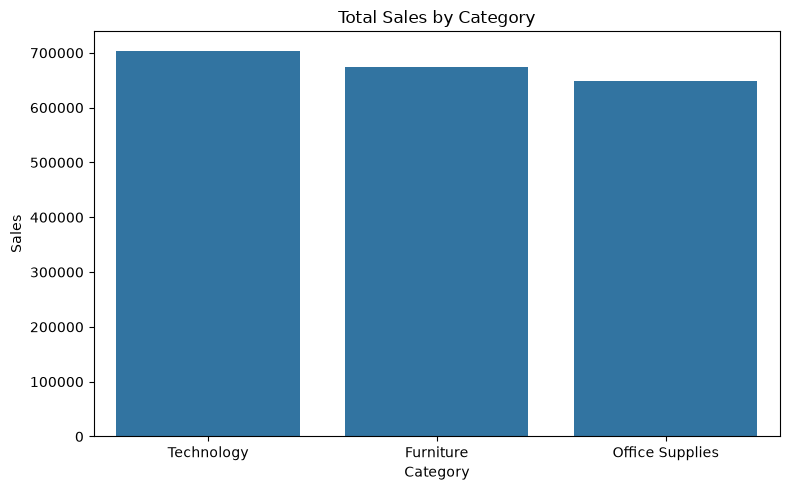

In [80]:
# STEP 50: Visualize Category-wise Sales
plt.figure(figsize = (8, 5))

sns.barplot(
    x = category_analysis.index,
    y = category_analysis["Sales"]
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

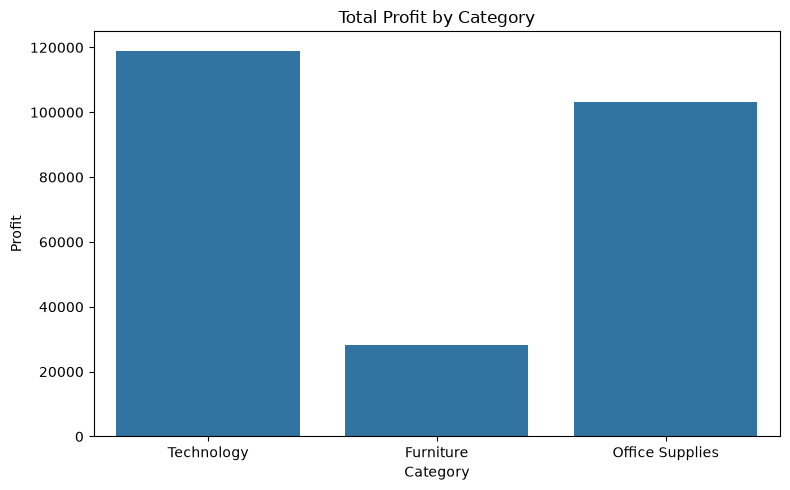

In [81]:
# STEP 51: Visualize Category-wise Profit
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Profit"]
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

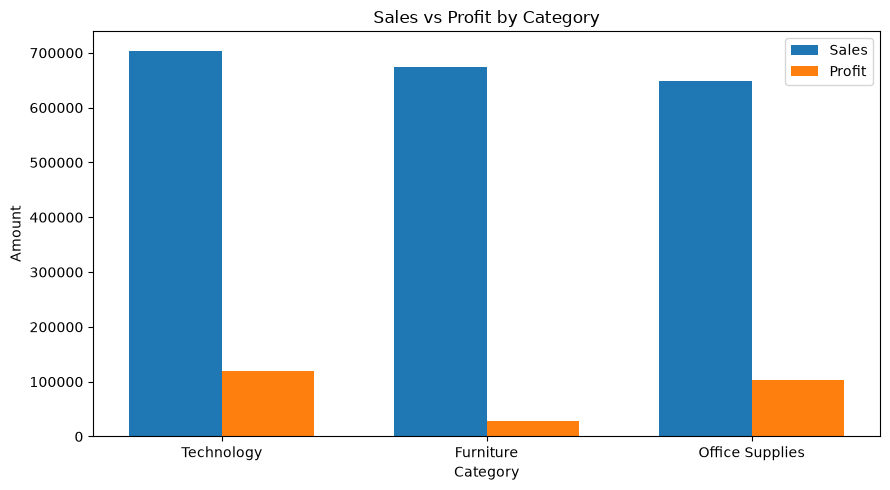

In [82]:
# STEP 52: Compare Sales and Profit by Category
category_comparison = category_analysis.reset_index()

plt.figure(figsize=(9, 5))

x = range(len(category_comparison))
width = 0.35

plt.bar(
    [i - width / 2 for i in x],
    category_comparison["Sales"],
    width=width,
    label="Sales"
)

plt.bar(
    [i + width / 2 for i in x],
    category_comparison["Profit"],
    width=width,
    label="Profit"
)

plt.xticks(x, category_comparison["Category"])
plt.title("Sales vs Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.legend()

plt.tight_layout()
plt.show()

In [83]:
# STEP 53: Analyze Sales and Profit by Sub-Category
subcategory_analysis = (
    df.groupby("Sub-Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

subcategory_analysis

,Sales,Profit
Sub-Category,,
Chairs,295578.8910,23391.6510
Phones,281660.5200,36793.2600
Storage,198329.8960,18495.4306
Tables,185578.0425,-15525.8611
Binders,179071.5640,23727.2479
Machines,176782.6150,8753.9726
Accessories,140780.0960,35340.8480
Copiers,125968.3140,48898.9242
Bookcases,104393.8797,-2844.1833


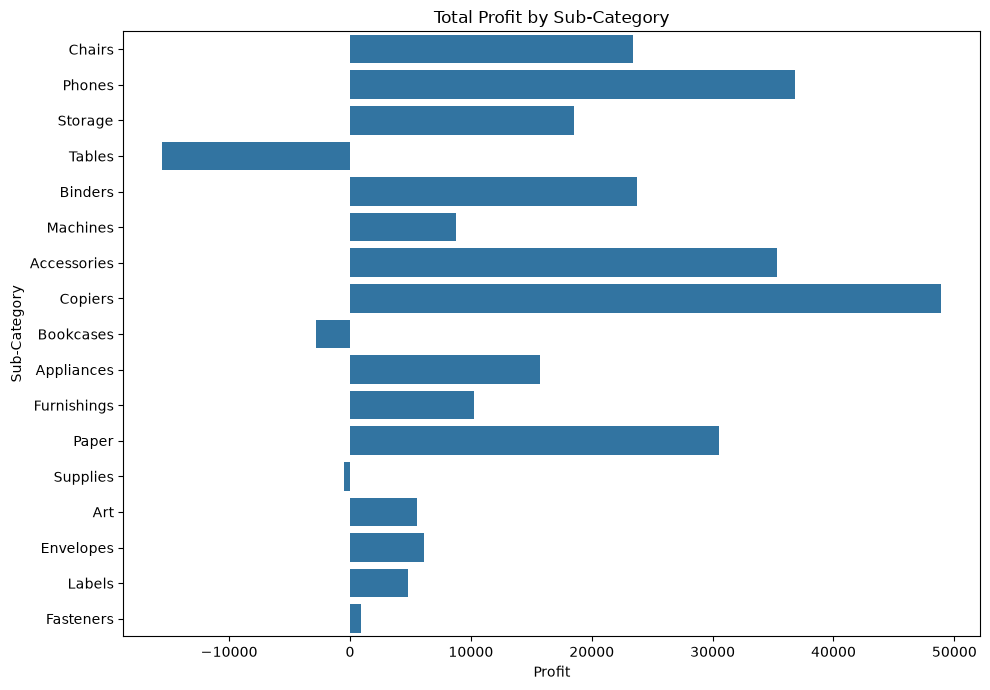

In [84]:
# STEP 54: Visualize Profit by Sub-Category
plt.figure(figsize=(10, 7))

sns.barplot(
    data=subcategory_analysis.reset_index(),
    x="Profit",
    y="Sub-Category"
)

plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

In [85]:
# STEP 55: Analyze Sales and Profit by Region
region_analysis = (
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

region_analysis

,Sales,Profit
Region,,
West,648553.5655,93376.4790
East,567299.8892,75919.5444
Central,444779.6550,36221.7793
South,366844.6975,44844.7649


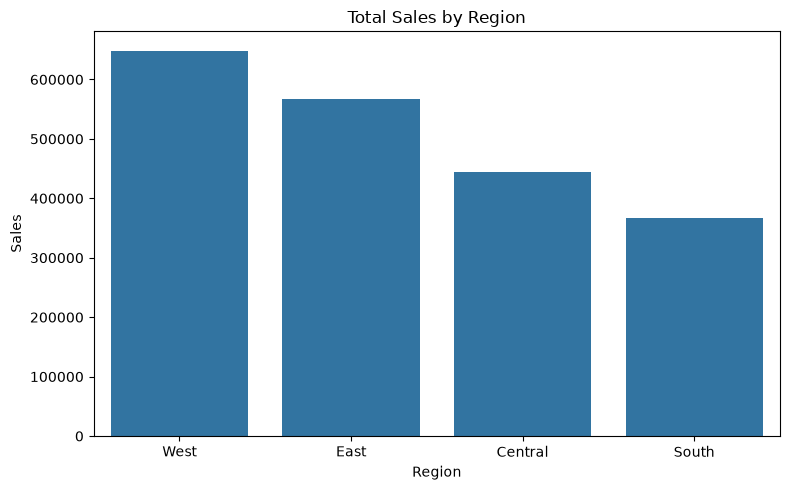

In [86]:
# STEP 56: Visualize Sales by Region
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

In [88]:
# STEP 57: Analyze monthly Sales trend
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales.head()

Order Date
2014-01    13218.303
2014-02     4391.122
2014-03    54277.537
2014-04    26734.389
2014-05    19840.476
Freq: M, Name: Sales, dtype: float64

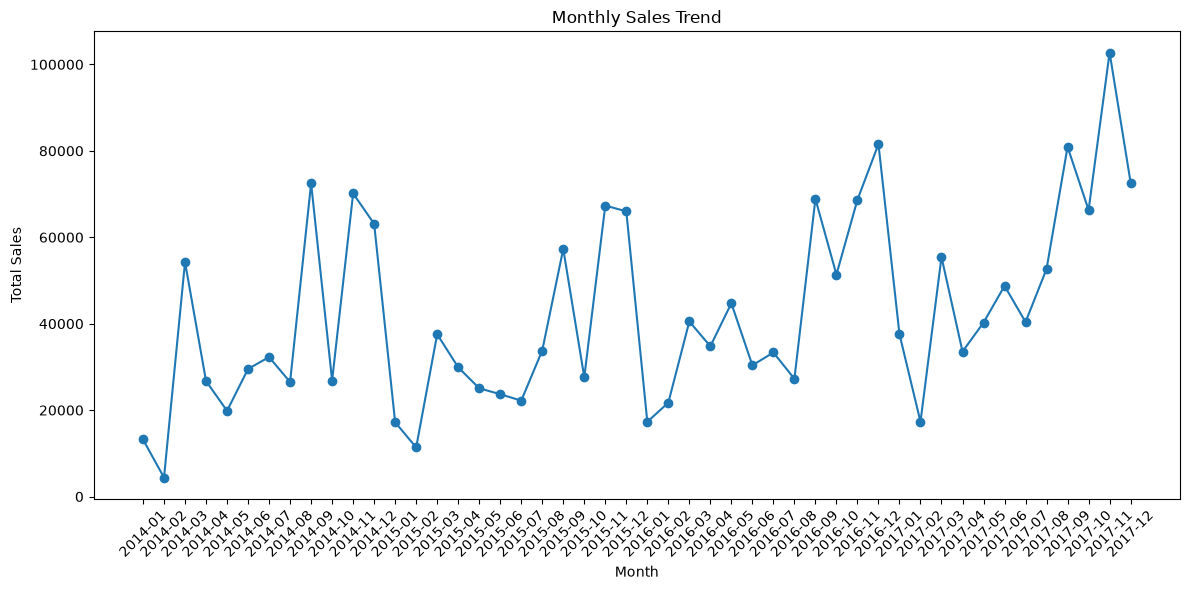

In [89]:
# STEP 58: Visualize the monthly Sales trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [90]:
# STEP 59: Analyze monthly Profit trend
monthly_profit = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Profit"]
    .sum()
)

monthly_profit.head()

Order Date
2014-01    2657.2370
2014-02     809.9510
2014-03      96.0548
2014-04    3251.8693
2014-05    2770.7129
Freq: M, Name: Profit, dtype: float64

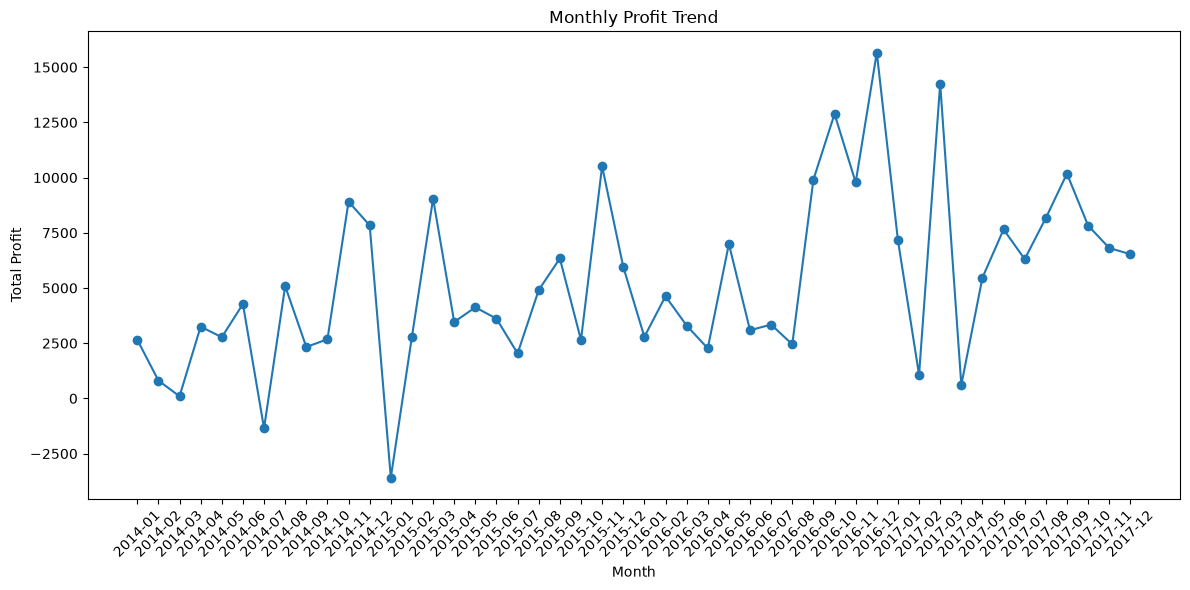

In [91]:
# STEP 60: Visualize the monthly Profit trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_profit.index.astype(str),
    monthly_profit.values,
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [92]:
# STEP 61: Find the Top 10 Customers by Sales
top_customers = (
    df.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer Name
Sean Miller      25013.658
Becky Martin     19622.552
Tamara Chand     18316.238
Raymond Buch     15019.091
Tom Ashbrook     14166.750
Ken Lonsdale     13755.871
Adrian Barton    13356.977
Hunter Lopez     12873.298
Sanjit Engle     12155.454
Greg Tran        11501.730
Name: Sales, dtype: float64

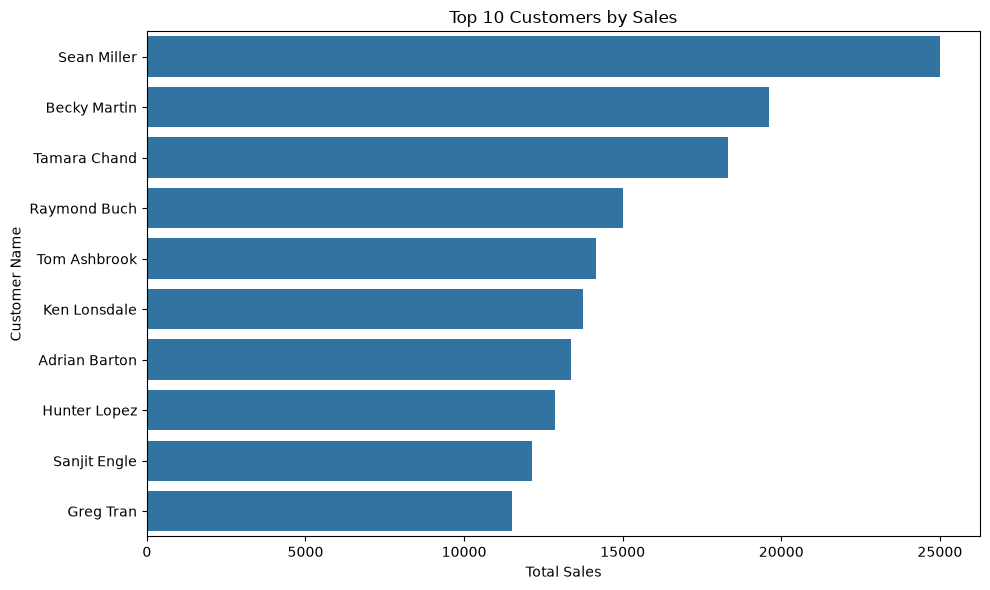

In [93]:
# STEP 62: Visualize the Top 10 Customers by Sales
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_customers.values,
    y=top_customers.index
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.show()

In [94]:
# STEP 63: Find the Top 10 Customers by Profit
top_profit_customers = (
    df.groupby("Customer Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_profit_customers

Customer Name
Tamara Chand            8650.1329
Raymond Buch            6951.5453
Hunter Lopez            5622.4292
Adrian Barton           4946.0646
Tom Ashbrook            4665.8331
Christopher Martinez    3885.1046
Keith Dawkins           2983.0636
Andy Reiter             2884.6208
Tom Boeckenhauer        2798.3689
Nathan Mautz            2746.1521
Name: Profit, dtype: float64

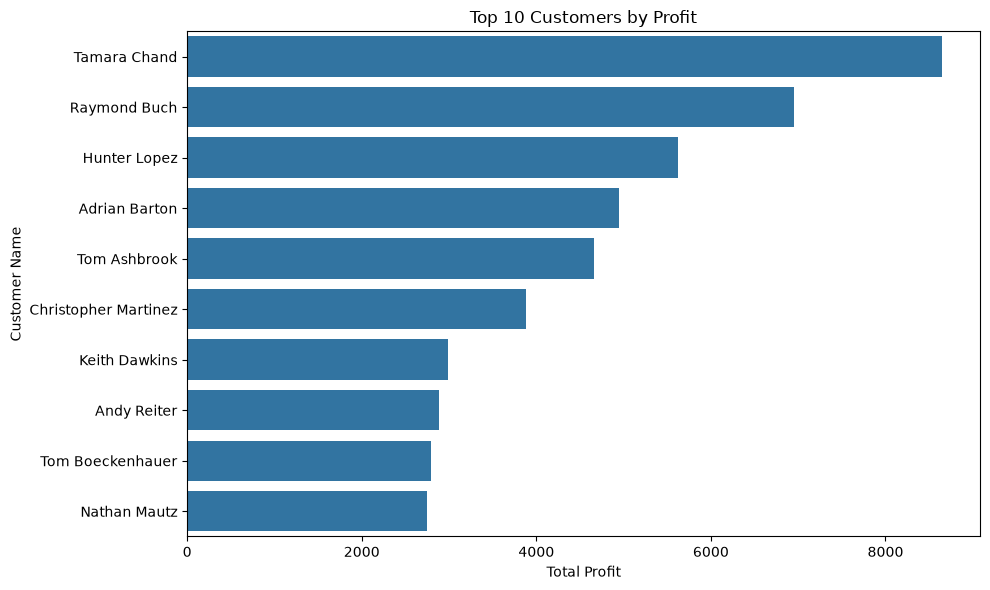

In [95]:
# STEP 64: Visualize the Top 10 Customers by Profit
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_profit_customers.values,
    y=top_profit_customers.index
)

plt.title("Top 10 Customers by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.show()

In [96]:
# STEP 65: Analyze Sales and Profit by Segment
segment_analysis = (
    df.groupby("Segment")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

segment_analysis

,Sales,Profit
Segment,,
Consumer,959541.9344,113503.6471
Corporate,654954.2433,81048.7563
Home Office,393182.0005,53236.8098
Unknown,19799.6290,2573.3544


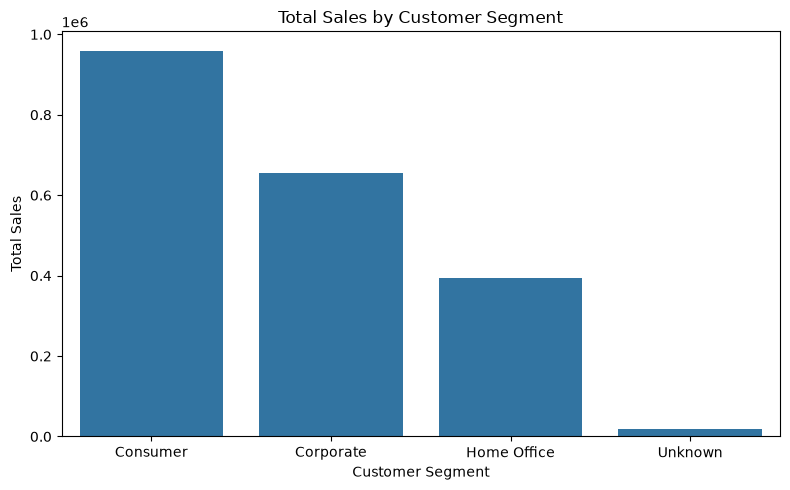

In [97]:
# STEP 66: Visualize Sales by Customer Segment
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis.reset_index(),
    x="Segment",
    y="Sales"
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

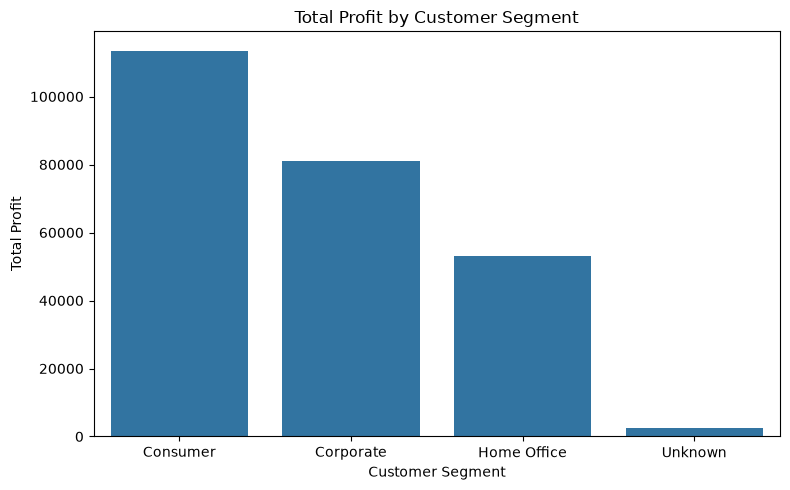

In [98]:
# STEP 67: Visualize Profit by Customer Segment
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis.reset_index(),
    x="Segment",
    y="Profit"
)

plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

In [99]:
# STEP 68: Analyze Sales and Profit by Ship Mode
ship_mode_analysis = (
    df.groupby("Ship Mode")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

ship_mode_analysis


,Sales,Profit
Ship Mode,,
Standard Class,1.129464e+06,134559.1939
Second Class,4.430324e+05,62473.9013
First Class,2.885015e+05,35447.9585
Same Day,1.560431e+05,17293.9123
Unknown,1.043654e+04,587.6016


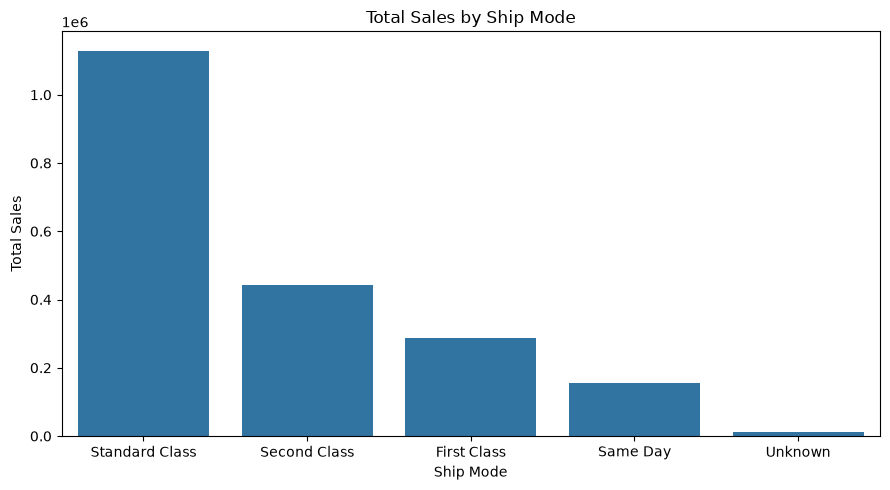

In [100]:
# STEP 69: Visualize Sales by Ship Mode
plt.figure(figsize=(9, 5))

sns.barplot(
    data=ship_mode_analysis.reset_index(),
    x="Ship Mode",
    y="Sales"
)

plt.title("Total Sales by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [101]:
# STEP 70: Analyze Profit by Discount Level
discount_profit = (
    df.groupby("Discount")["Profit"]
    .mean()
    .sort_index()
)

discount_profit

Discount
0.00     66.585708
0.10    101.830827
0.15     28.171784
0.20     24.919728
0.30    -45.584759
0.32    -92.419812
0.40   -128.886876
0.45   -211.008010
0.50   -326.170979
0.60    -43.415636
0.70    -83.838016
0.80   -107.648233
Name: Profit, dtype: float64

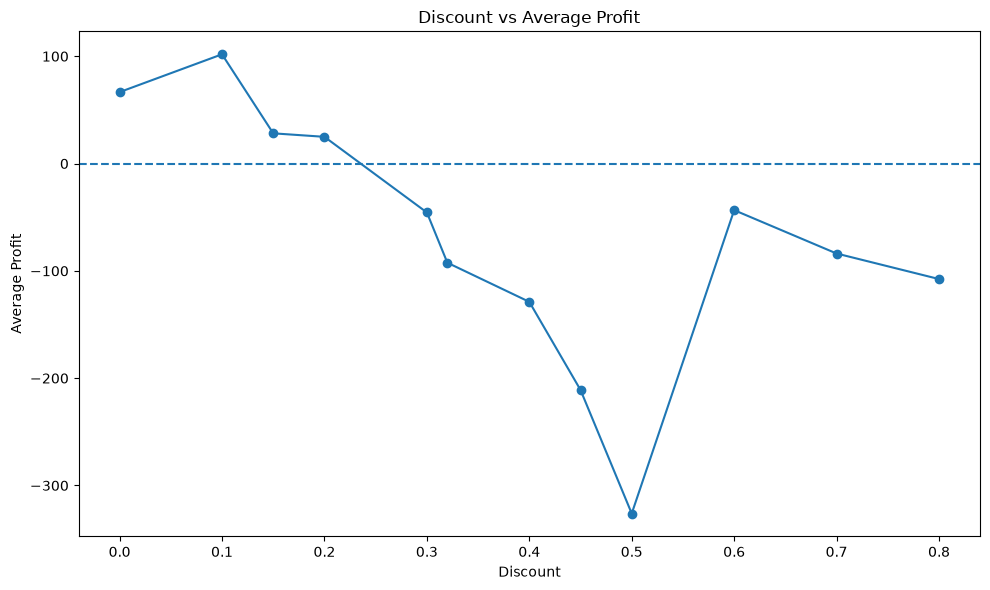

In [102]:
# STEP 71: Visualize the relationship between Discount
plt.figure(figsize=(10, 6))

plt.plot(
    discount_profit.index,
    discount_profit.values,
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Discount vs Average Profit")
plt.xlabel("Discount")
plt.ylabel("Average Profit")

plt.tight_layout()
plt.show()

In [103]:
# STEP 72: Analyze Sales and Profit by State
state_analysis = (
    df.groupby("State")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

state_analysis.head(10)

,Sales,Profit
State,,
California,399041.6785,67265.6861
New York,276021.3300,65257.9109
Texas,157773.8892,-24290.7772
Washington,125947.8000,29686.1845
Pennsylvania,95072.3550,-14716.2084
Florida,77556.8505,-3701.1316
Michigan,72116.5980,23453.7396
Illinois,68940.9980,-12813.5331
Ohio,66968.0690,-9643.1389


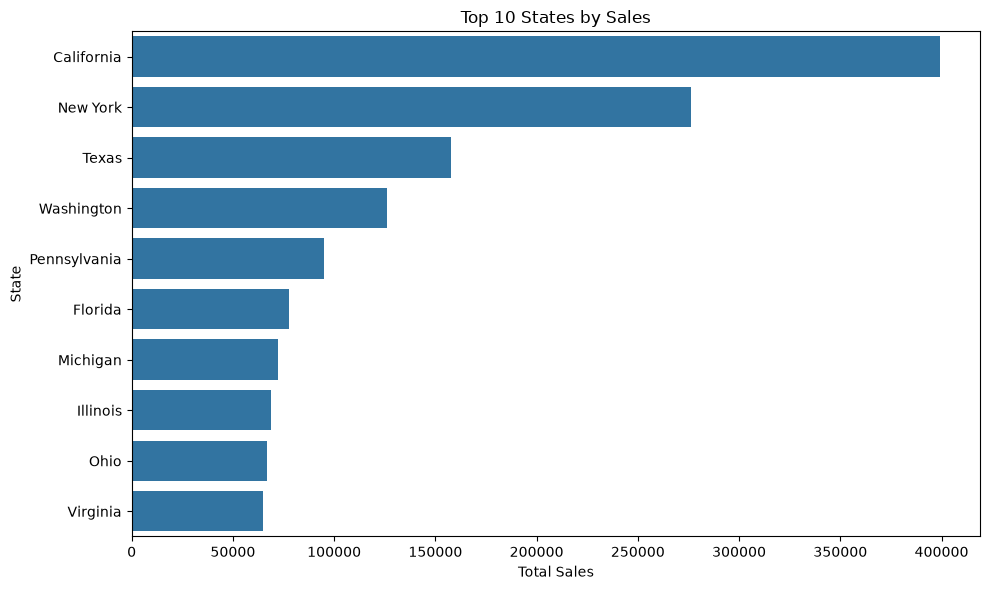

In [104]:
# STEP 73: Visualize the Top 10 States by Sales
top_states_sales = state_analysis.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_states_sales["Sales"],
    y=top_states_sales.index
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [105]:
# STEP 74: Find the Top 10 States by Profit
top_states_profit = (
    state_analysis
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_states_profit

,Sales,Profit
State,,
California,399041.6785,67265.6861
New York,276021.3300,65257.9109
Washington,125947.8000,29686.1845
Michigan,72116.5980,23453.7396
Virginia,65096.0900,16882.5160
Indiana,49316.8400,16568.8540
Georgia,41889.7400,14289.6320
Kentucky,34206.0600,10389.1160
New Jersey,31898.2320,9309.1858


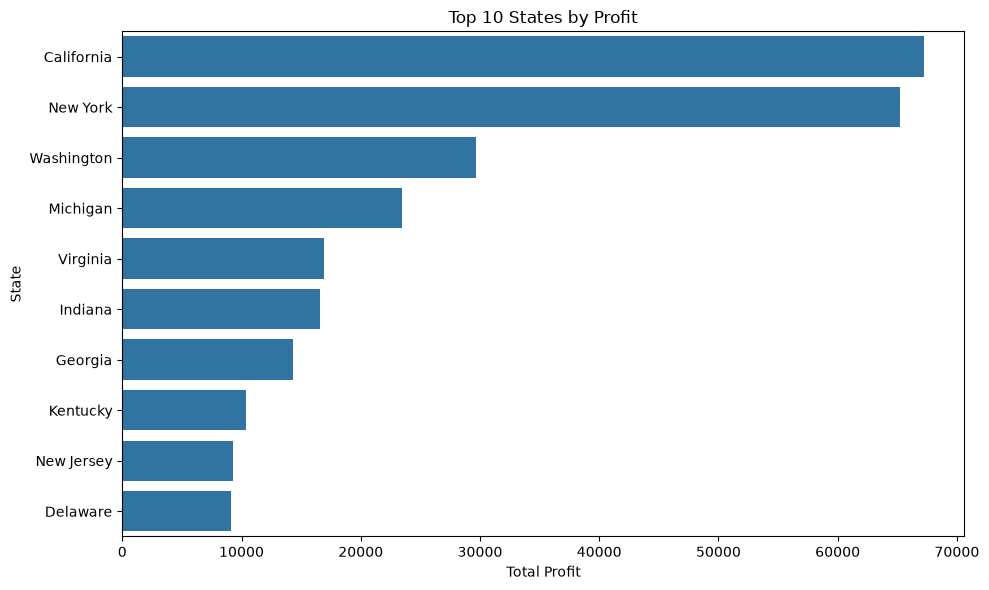

In [106]:
# STEP 75: Visualize the Top 10 States by Profit
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_states_profit["Profit"],
    y=top_states_profit.index
)

plt.title("Top 10 States by Profit")
plt.xlabel("Total Profit")
plt.ylabel("State")

plt.tight_layout()
plt.show()

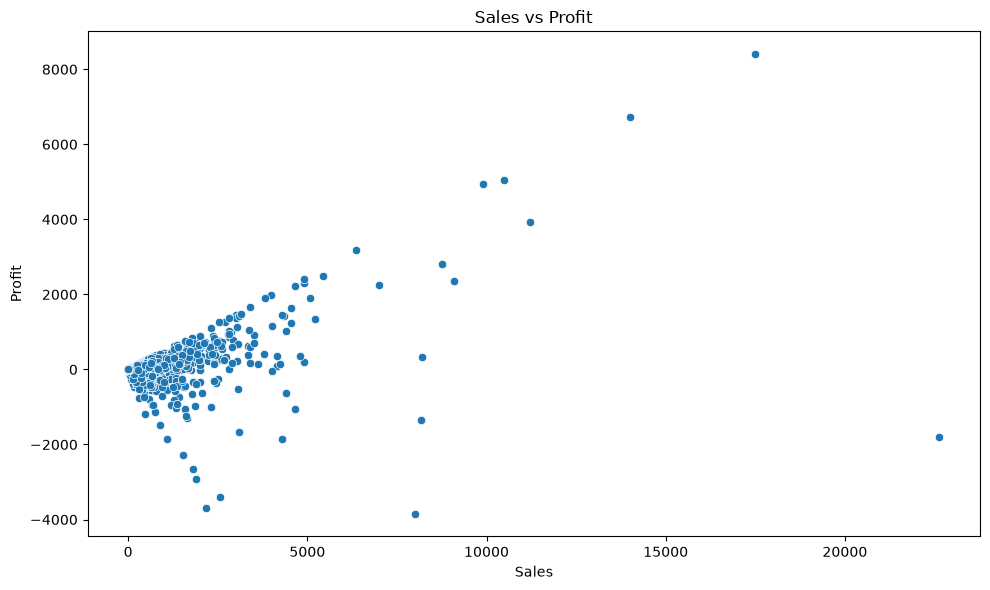

In [107]:
# STEP 76: Analyze the relationship between Sales and Profit
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit"
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

## Final Business Insights

1. West region generated the highest total Sales and Profit among all regions.

2. Technology generated the highest Sales and Profit among the three main product categories.

3. Chairs generated the highest Sales among sub-categories, while Copiers generated the highest Profit.

4. Tables, Bookcases, and Supplies generated negative total Profit and should be investigated further.

5. Consumer segment generated the highest Sales and Profit among the customer segments.

6. Standard Class generated the highest Sales and Profit among the shipping modes.

7. Higher discount levels were generally associated with lower average Profit in this dataset. Discounts of 30% or more showed negative average Profit.

8. California generated the highest Sales and Profit among the states analyzed.

9. Some states such as Texas, Pennsylvania, Illinois, and Ohio generated substantial Sales but negative total Profit.

10. The Top Sales customer and Top Profit customer were different, showing that customer revenue contribution and customer profitability should be analyzed separately.

In [110]:
# STEP 78: Save the final cleaned dataset
df.to_excel("Retail_Superstore_Cleaned.xlsx", index=False)

print("Final cleaned dataset saved successfully.")

Final cleaned dataset saved successfully.
